<div style="border:solid green 2px; padding: 20px">
<b>Iteration - 1</b><br>
<b>Reviewer’s comments</b><br>

Hello Obed!,
  
I am Alexangel, your reviewer in this first iteration,
  
Another project successfully completed - well done! 🏆 Your consistent effort and progress are truly commendable.

Our team is here to help you keep pushing forward and honing your skills as you advance through the program.

My new comments are marked as `Reviewer's comment`. You can contact me via Tripleten Hub for further feedback. This information is described below.

**What Was Great**:
- Good job on following the structure of the project.

**Tips for Future Projects**:
- Consider adding brief comments after the analysis or graph of every dataframe to make your work even more integral.

</div>

-------------------------------------------------------------------------------------------------------------

***Name of the reviewer***: Alexangel Bracho

***Reviewer’s Tripleten Hub link*** : [reviewer's link](https://hub.tripleten.com/u/6b1cbe37)

-------------------------------------------------------------------------------------------------------------

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, accuracy_score, roc_curve

In [2]:
data_dir_candidates = [
    Path("/datasets/final_provider"),
    Path("/Users/apple/Downloads/final_provider"),
]

for d in data_dir_candidates:
    if d.exists():
        data_dir = d
        break
else:
    raise FileNotFoundError("Could not find final_provider folder.")

contract = pd.read_csv(data_dir / "contract.csv")
personal = pd.read_csv(data_dir / "personal.csv")
internet = pd.read_csv(data_dir / "internet.csv")
phone = pd.read_csv(data_dir / "phone.csv")

print("Using data:", data_dir)
print(contract.shape, personal.shape, internet.shape, phone.shape)

Using data: /datasets/final_provider
(7043, 8) (7043, 5) (5517, 8) (6361, 2)


<div class="alert alert-block alert-success">
<b>Reviewer's comment</b> <a class="tocSkip"></a>

Good job loading the datasets.

</div>

In [3]:
df = (
    contract
    .merge(personal, on="customerID", how="left")
    .merge(internet, on="customerID", how="left")
    .merge(phone, on="customerID", how="left")
)

snapshot_date = pd.Timestamp("2020-02-01")

# target: churn = 1 if client left
df["Binary_EndDate"] = (df["EndDate"] != "No").astype(int)

df["BeginDate"] = pd.to_datetime(df["BeginDate"], errors="coerce")
df["BeginMonth"] = df["BeginDate"].dt.to_period("M").astype(str)
df["TenureDays"] = (snapshot_date - df["BeginDate"]).dt.days
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Merged shape:", df.shape)
print("Unique customerID:", df["customerID"].nunique())
print("Duplicate customerID:", df.duplicated("customerID").sum())

print("\nMissing values (top):")
display(df.isna().sum().sort_values(ascending=False).head(15))

Merged shape: (7043, 23)
Unique customerID: 7043
Duplicate customerID: 0

Missing values (top):


InternetService     1526
StreamingMovies     1526
StreamingTV         1526
TechSupport         1526
DeviceProtection    1526
OnlineBackup        1526
OnlineSecurity      1526
MultipleLines        682
TotalCharges          11
customerID             0
BeginMonth             0
Binary_EndDate         0
Dependents             0
BeginDate              0
Partner                0
dtype: int64

<div class="alert alert-block alert-success">
<b>Reviewer's comment</b> <a class="tocSkip"></a>

Great work merging the dataframes, converting some datatypes, feature engineering and checking the missing values and the duplicate values.

</div>

In [4]:
internet_cols = [
    "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies"
]
for c in internet_cols:
    if c in df.columns:
        df[c] = df[c].fillna("No internet service")

if "MultipleLines" in df.columns:
    df["MultipleLines"] = df["MultipleLines"].fillna("No phone service")


,MonthlyCharges,TotalCharges,TenureDays
count,7043.000000,7032.000000,7043.000000
mean,64.761692,2283.300441,1006.457050
std,30.090047,2266.771362,736.596428
min,18.250000,18.800000,0.000000
25%,35.500000,401.450000,306.000000
50%,70.350000,1397.475000,883.000000
75%,89.850000,3794.737500,1706.000000
max,118.750000,8684.800000,2314.000000


Target distribution:


0    5174
1    1869
Name: Binary_EndDate, dtype: int64

Churn rate: 26.54 %


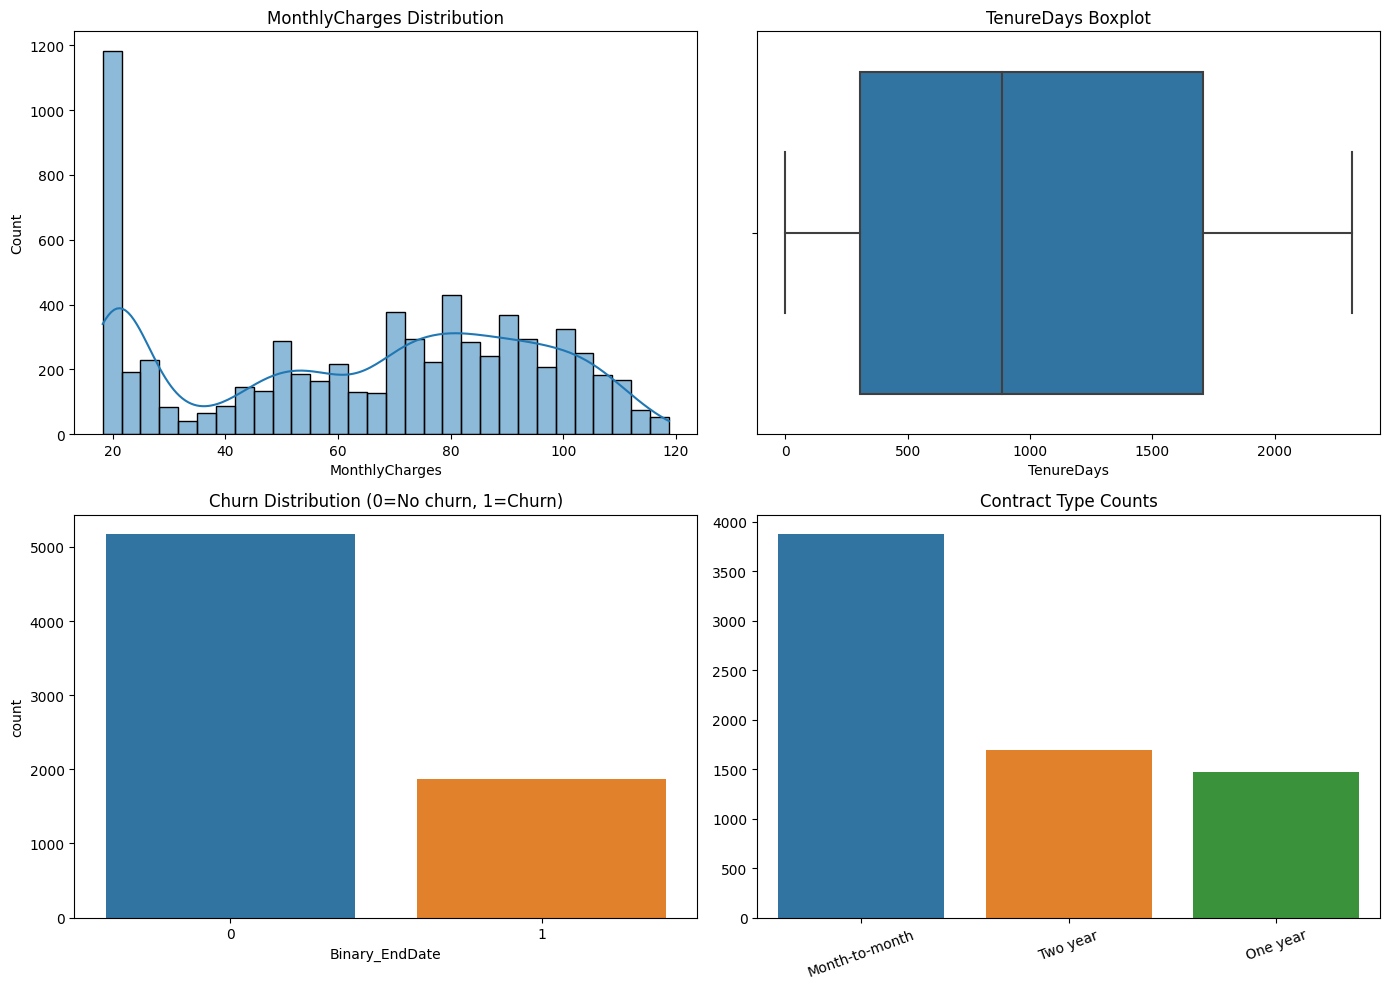

In [5]:
display(df[["MonthlyCharges", "TotalCharges", "TenureDays"]].describe())

print("Target distribution:")
display(df["Binary_EndDate"].value_counts())
print("Churn rate:", round(df["Binary_EndDate"].mean() * 100, 2), "%")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(df["MonthlyCharges"], bins=30, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("MonthlyCharges Distribution")

sns.boxplot(x=df["TenureDays"], ax=axes[0, 1])
axes[0, 1].set_title("TenureDays Boxplot")

sns.countplot(x="Binary_EndDate", data=df, ax=axes[1, 0])
axes[1, 0].set_title("Churn Distribution (0=No churn, 1=Churn)")

type_counts = df["Type"].value_counts()
sns.barplot(x=type_counts.index, y=type_counts.values, ax=axes[1, 1])
axes[1, 1].set_title("Contract Type Counts")
axes[1, 1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

,churn_rate,count
Type,,
Month-to-month,42.71,3875
One year,11.27,1473
Two year,2.83,1695


,churn_rate,count
PaymentMethod,,
Electronic check,45.29,2365
Mailed check,19.11,1612
Bank transfer (automatic),16.71,1544
Credit card (automatic),15.24,1522


,churn_rate,count
InternetService,,
Fiber optic,41.89,3096
DSL,18.96,2421
No internet service,7.40,1526


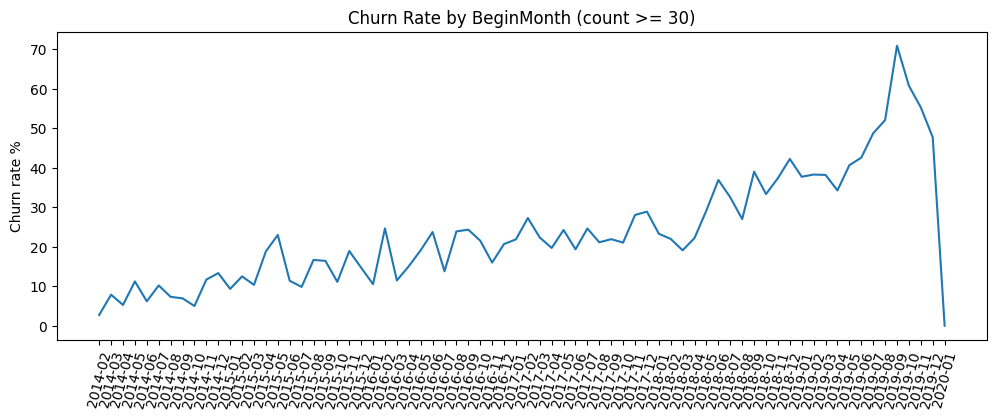

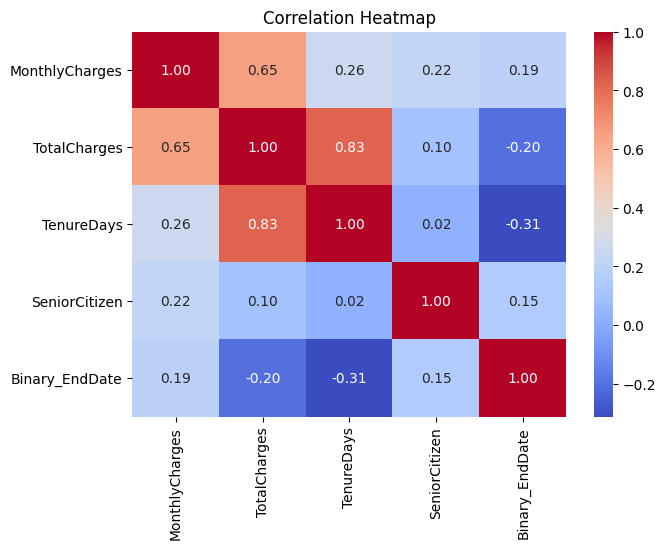

In [6]:
def churn_rate_table(col):
    out = (
        df.groupby(col)["Binary_EndDate"]
        .agg(churn_rate="mean", count="size")
        .sort_values("churn_rate", ascending=False)
    )
    out["churn_rate"] = (out["churn_rate"] * 100).round(2)
    return out

display(churn_rate_table("Type"))
display(churn_rate_table("PaymentMethod"))
display(churn_rate_table("InternetService"))

month_tbl = df.groupby("BeginMonth")["Binary_EndDate"].agg(churn_rate="mean", count="size")
month_tbl = month_tbl[month_tbl["count"] >= 30].sort_index()
month_tbl["churn_rate"] = month_tbl["churn_rate"] * 100

plt.figure(figsize=(12, 4))
plt.plot(month_tbl.index, month_tbl["churn_rate"])
plt.xticks(rotation=75)
plt.title("Churn Rate by BeginMonth (count >= 30)")
plt.ylabel("Churn rate %")
plt.show()

corr_cols = ["MonthlyCharges", "TotalCharges", "TenureDays", "SeniorCitizen", "Binary_EndDate"]
corr = df[corr_cols].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()


<div class="alert alert-block alert-success">
<b>Reviewer's comment</b> <a class="tocSkip"></a>

Good job with the Exploratory Data Analysis (EDA).

</div>

In [7]:
drop_cols = ["customerID", "EndDate", "BeginDate", "Binary_EndDate"]
X = df.drop(columns=drop_cols, errors="ignore")
y = df["Binary_EndDate"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X shape:", X.shape)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Train churn rate:", round(y_train.mean(), 4))
print("Test churn rate :", round(y_test.mean(), 4))

num_cols = X_train.select_dtypes(include=["number"]).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=["number"]).columns.tolist()
print("Numeric columns:", len(num_cols))
print("Categorical columns:", len(cat_cols))

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, num_cols),
    ("cat", categorical_pipe, cat_cols)
])

X shape: (7043, 19)
Train: (5634, 19) Test: (1409, 19)
Train churn rate: 0.2654
Test churn rate : 0.2654
Numeric columns: 4
Categorical columns: 15


<div class="alert alert-block alert-success">
<b>Reviewer's comment</b> <a class="tocSkip"></a>

Good job with splitting your data, creating the pipelines for the pre-processing stage.

</div>

Dummy (most_frequent): AUC-ROC=0.5000 | Accuracy=0.7346
LogisticRegression (balanced): AUC-ROC=0.8518 | Accuracy=0.7509


,model,auc_roc,accuracy
1,LogisticRegression (balanced),0.851815,0.750887
0,Dummy (most_frequent),0.500000,0.734564


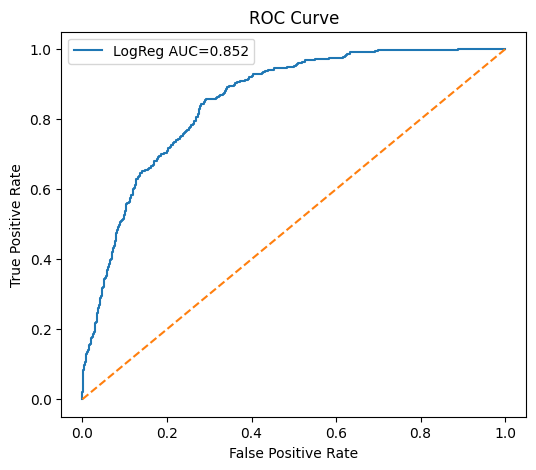

In [8]:
def evaluate(name, model):
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    pred = model.predict(X_test)
    auc = roc_auc_score(y_test, proba)
    acc = accuracy_score(y_test, pred)
    print(f"{name}: AUC-ROC={auc:.4f} | Accuracy={acc:.4f}")
    return {"model": name, "auc_roc": auc, "accuracy": acc}

dummy_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", DummyClassifier(strategy="most_frequent"))
])

logreg_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42))
])

results = []
results.append(evaluate("Dummy (most_frequent)", dummy_pipe))
results.append(evaluate("LogisticRegression (balanced)", logreg_pipe))

results_df = pd.DataFrame(results).sort_values("auc_roc", ascending=False)
display(results_df)

# ROC curve for best baseline
logreg_pipe.fit(X_train, y_train)
proba_lr = logreg_pipe.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, proba_lr)
auc_lr = roc_auc_score(y_test, proba_lr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"LogReg AUC={auc_lr:.3f}")
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

<div class="alert alert-block alert-success">
<b>Reviewer's comment</b> <a class="tocSkip"></a>

Great work with training your model and the dummy model, the results and the visualization.

</div>